# 🛰️ Punjab GeoGuardian – Urban Expansion & Farmland Loss Detection
**AIRI Team PITB – AI Internship Task 3** | Sentinel-2 + Google Earth Engine + Random Forest

**How to run:** Runtime → Run all *up to Step 5*. Then label the 2 CSV files (see Step 5), upload them (Step 6) and run the rest.
All outputs are saved to Google Drive → `MyDrive/PunjabGeoGuardian/outputs`.

⚠️ Learning prototype, not an official government system. Use words like *possible conversion / estimated change*.

## Step 1 – Setup & Config (edit only the CONFIG block)

In [1]:
!pip -q install geemap folium scikit-learn pandas matplotlib tabulate markdown pillow

In [6]:
# ================== CONFIG ==================
EE_PROJECT = 'punjab-geoguardian-123456'     # your Earth Engine enabled Google Cloud project
AOI_NAME   = 'Lahore peri-urban zone (Raiwind Road corridor)'
AOI_BBOX   = [74.18, 31.30, 74.29, 31.41]    # [west, south, east, north] ~ 125 sq km
Y1, Y2     = 2019, 2025
DATE_RANGES = {2019: ('2019-01-15', '2019-03-31'),   # same season both years (wheat peak)
               2025: ('2025-01-15', '2025-03-31')}
CLOUD_MAX  = 20
THR = dict(ndvi_veg=0.35, ndvi_built_max=0.25, ndbi_built=-0.02, mndwi_water=0.10)  # tune after validation
N_TRAIN_PER_CLASS = 70
N_VALID_PER_CLASS = 25
# ============================================

from google.colab import drive, files
drive.mount('/content/drive')
OUT = '/content/drive/MyDrive/PunjabGeoGuardian/outputs'
import os, io, re, json, base64, requests
os.makedirs(f'{OUT}/maps', exist_ok=True)
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image
import ee
import geemap

ee.Authenticate()
ee.Initialize(project=EE_PROJECT)
json.dump(dict(aoi_name=AOI_NAME, y1=Y1, y2=Y2, bbox=AOI_BBOX,
               dates={str(k): v for k, v in DATE_RANGES.items()},
               cloud_max=CLOUD_MAX, thresholds=THR),
          open(f'{OUT}/config.json', 'w'), indent=2)
print('Ready ✔')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Ready ✔


## Step 2 – AOI, Sentinel-2 composites (date + cloud filter + median + clip) and RGB maps

2019: 13 scenes (2019-01-15 to 2019-03-31), cloud < 20%
2025: 17 scenes (2025-01-15 to 2025-03-31), cloud < 20%


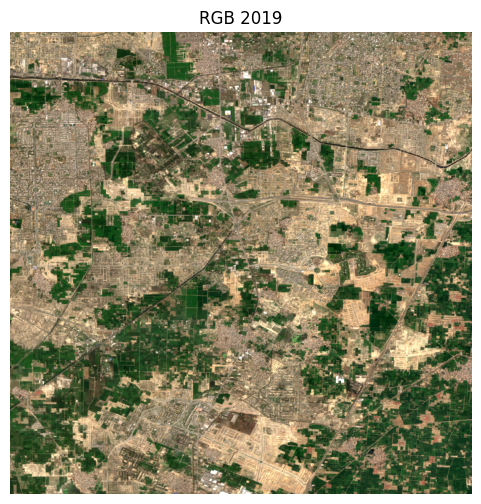

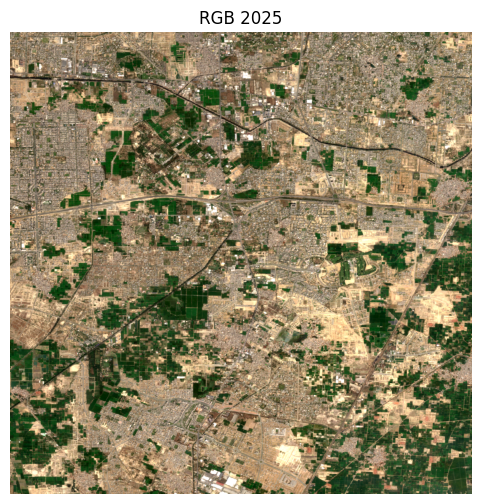

In [7]:
aoi = ee.Geometry.Rectangle(AOI_BBOX)
S2 = 'COPERNICUS/S2_SR_HARMONIZED'
BANDS = ['B2', 'B3', 'B4', 'B8', 'B11']

def mask_clouds(img):
    scl = img.select('SCL')   # keep vegetation(4), bare(5), water(6), unclassified(7); drop shadow/cloud/cirrus
    ok = scl.eq(4).Or(scl.eq(5)).Or(scl.eq(6)).Or(scl.eq(7))
    return img.updateMask(ok).select(BANDS).divide(10000)

def add_indices(img):
    ndvi = img.normalizedDifference(['B8', 'B4']).rename('NDVI')     # (NIR-Red)/(NIR+Red)
    ndbi = img.normalizedDifference(['B11', 'B8']).rename('NDBI')    # (SWIR-NIR)/(SWIR+NIR)
    mndwi = img.normalizedDifference(['B3', 'B11']).rename('MNDWI')  # water helper
    return img.addBands([ndvi, ndbi, mndwi])

def get_composite(year):
    s, e = DATE_RANGES[year]
    col = (ee.ImageCollection(S2).filterBounds(aoi).filterDate(s, e)
           .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', CLOUD_MAX)))
    n = col.size().getInfo()
    assert n > 0, f'No scenes for {year}; widen the date range or cloud limit'
    print(f'{year}: {n} scenes ({s} to {e}), cloud < {CLOUD_MAX}%')
    return add_indices(col.map(mask_clouds).median().clip(aoi)), n

im1, n1 = get_composite(Y1)
im2, n2 = get_composite(Y2)

RGB_VIS  = dict(bands=['B4', 'B3', 'B2'], min=0.02, max=0.25, gamma=1.2)
NDVI_VIS = dict(min=-0.1, max=0.8, palette=['d73027', 'fee08b', '1a9850'])
NDBI_VIS = dict(min=-0.4, max=0.3, palette=['2166ac', 'f7f7f7', 'b2182b'])
CLS_VIS  = dict(min=0, max=2, palette=['2e7d32', 'd32f2f', 'f9d71c'])
NAMES = {0: 'Vegetation/Agriculture', 1: 'Built-up/Urban', 2: 'Other'}

def save_map(img, vis, title, fname, legend=False):
    vimg = img.visualize(**vis) if vis else img
    url = vimg.getThumbURL({'region': aoi, 'dimensions': 900, 'format': 'png'})
    im = Image.open(io.BytesIO(requests.get(url, timeout=180).content))
    im.save(f'{OUT}/maps/{fname}.png')
    plt.figure(figsize=(6, 6)); plt.imshow(im); plt.title(title); plt.axis('off')
    if legend:
        cols = ['#2e7d32', '#d32f2f', '#f9d71c']
        plt.legend(handles=[mpatches.Patch(color=c, label=NAMES[i]) for i, c in enumerate(cols)],
                   loc='lower center', bbox_to_anchor=(0.5, -0.12), ncol=3, fontsize=7)
    plt.show()

save_map(im1, RGB_VIS, f'RGB {Y1}', f'rgb_{Y1}')
save_map(im2, RGB_VIS, f'RGB {Y2}', f'rgb_{Y2}')

## Step 3 – NDVI & NDBI maps

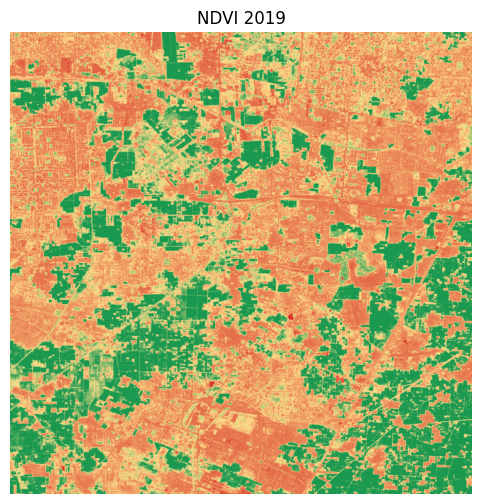

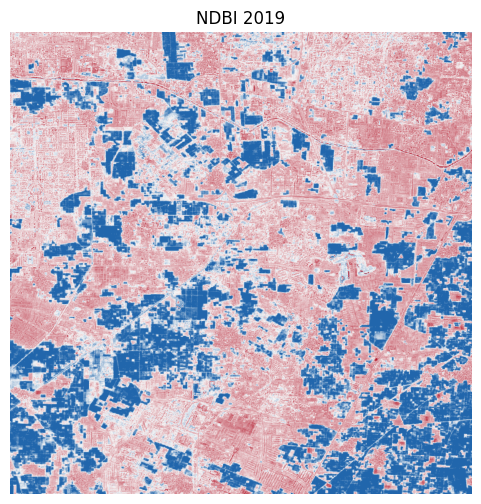

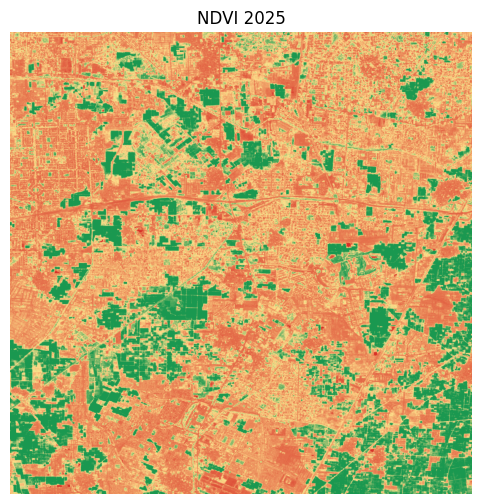

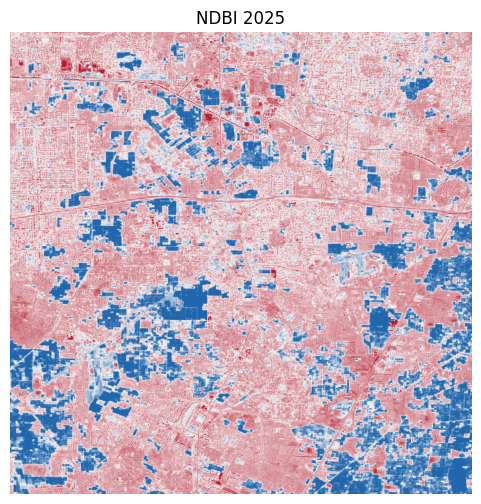

In [8]:
for y, im in [(Y1, im1), (Y2, im2)]:
    save_map(im.select('NDVI'), NDVI_VIS, f'NDVI {y}', f'ndvi_{y}')
    save_map(im.select('NDBI'), NDBI_VIS, f'NDBI {y}', f'ndbi_{y}')

## Step 4 – Rule-based classification (baseline, Week-1 deliverable)
0 = Vegetation/Agriculture, 1 = Built-up/Urban, 2 = Other (bare land, water, mixed)

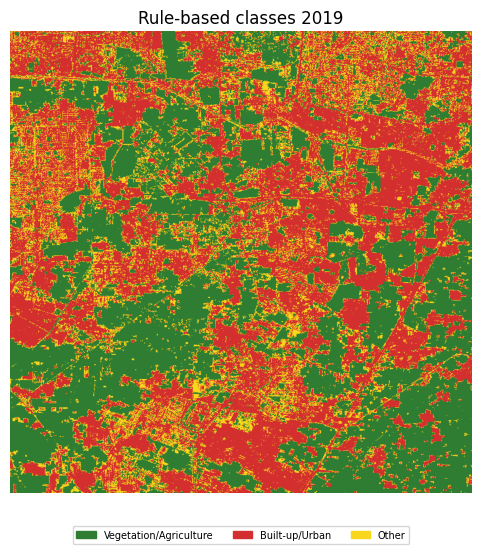

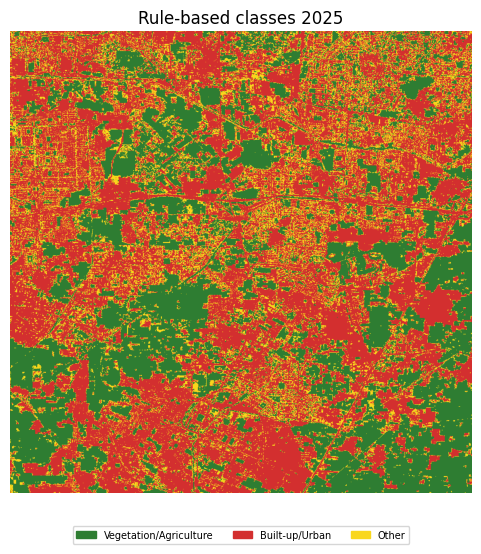

In [9]:
def classify_rules(img):
    ndvi, ndbi, mndwi = img.select('NDVI'), img.select('NDBI'), img.select('MNDWI')
    water = mndwi.gt(THR['mndwi_water'])
    veg = ndvi.gte(THR['ndvi_veg']).And(water.Not())
    built = ndvi.lt(THR['ndvi_built_max']).And(ndbi.gt(THR['ndbi_built'])).And(water.Not())
    cls = ee.Image(2).where(built, 1).where(veg, 0)
    return cls.rename('class').toByte().updateMask(img.select('B4').mask())

cls1_rule, cls2_rule = classify_rules(im1), classify_rules(im2)
save_map(cls1_rule, CLS_VIS, f'Rule-based classes {Y1}', f'class_rule_{Y1}', legend=True)
save_map(cls2_rule, CLS_VIS, f'Rule-based classes {Y2}', f'class_rule_{Y2}', legend=True)

## Step 5 – Create labelling templates (training + validation points)
Points are sampled **stratified** from the baseline map so that all 3 classes appear, and the validation points are kept ≥30 m away from training points.

**Your manual work (important – this is what sir checks):**
1. Open each CSV in Google Sheets/Excel. Click the `gmaps_link` of each point (Google satellite, higher resolution than Sentinel-2).
2. Training file → fill `label` with `Vegetation`, `Built-up` or `Other`. Need ≥ 50 per class.
3. Validation file → fill `actual_class` the same way + write a short `notes` (e.g. "crop field", "housing area", "bare soil"). **Label honestly, do not look at the model output.**
4. Save as `training_points_labeled.csv` / `validation_points_labeled.csv`.

In [10]:
def stratified_points(cls_img, per_class, seed):
    fc = cls_img.stratifiedSample(numPoints=0, classBand='class', region=aoi, scale=10, seed=seed,
                                  classValues=[0, 1, 2], classPoints=[per_class] * 3, geometries=True)
    feats = fc.getInfo()['features']
    return pd.DataFrame([dict(lon=round(f['geometry']['coordinates'][0], 6),
                              lat=round(f['geometry']['coordinates'][1], 6)) for f in feats])

train = stratified_points(cls2_rule, N_TRAIN_PER_CLASS, seed=1)
valid = stratified_points(cls2_rule, N_VALID_PER_CLASS, seed=2)

def dmin(r):
    return np.min(np.hypot((train.lon - r.lon) * 111320 * np.cos(np.radians(r.lat)), (train.lat - r.lat) * 110540))
valid = valid[valid.apply(dmin, axis=1) > 30]

def finish(df, label_col, seed):
    df = df.sample(frac=1, random_state=seed).reset_index(drop=True)
    df.insert(0, 'point_id', np.arange(1, len(df) + 1))
    df['gmaps_link'] = [f'https://www.google.com/maps/@{la},{lo},250m/data=!3m1!1e3' for la, lo in zip(df.lat, df.lon)]
    df[label_col] = ''
    if label_col == 'actual_class': df['notes'] = ''
    return df

train, valid = finish(train, 'label', 0), finish(valid, 'actual_class', 1)
train.to_csv(f'{OUT}/training_points_TEMPLATE.csv', index=False)
valid.to_csv(f'{OUT}/validation_points_TEMPLATE.csv', index=False)
print(len(train), 'training points |', len(valid), 'validation points (need >= 50 usable)')
files.download(f'{OUT}/training_points_TEMPLATE.csv'); files.download(f'{OUT}/validation_points_TEMPLATE.csv')

# ---- also show points on a map to check spread ----
m0 = geemap.Map(); m0.centerObject(aoi, 12); m0.add_basemap('SATELLITE')
m0.add_points_from_xy(train, x='lon', y='lat', layer_name='training') if hasattr(m0, 'add_points_from_xy') else None
m0

210 training points | 73 validation points (need >= 50 usable)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Map(center=[31.35500100659, 74.23500000000168], controls=(WidgetControl(options=['position', 'transparent_bg']…

## Step 6 – Upload the labelled CSVs
Run the cell and select both files (file names must contain `training` / `validation`).

In [11]:
up = files.upload()
for name, data in up.items():
    key = 'training' if 'train' in name.lower() else 'validation'
    open(f'{OUT}/{key}_points_labeled.csv', 'wb').write(data)
    print('saved', key)

Saving training_points_labeled.csv.csv to training_points_labeled.csv.csv
Saving validation_points_labeled.csv.csv to validation_points_labeled.csv.csv
saved training
saved validation


## Step 7 – Random Forest classification (falls back to rule-based if no training file)

Training samples per class:
 class
0    54
1    62
2    80
Name: count, dtype: int64


Hold-out (30%) accuracy of RF on training samples: 0.392
METHOD = Random Forest (200 trees; features: B2, B3, B4, B8, B11, NDVI, NDBI), trained on 196 manually labelled points from 2025


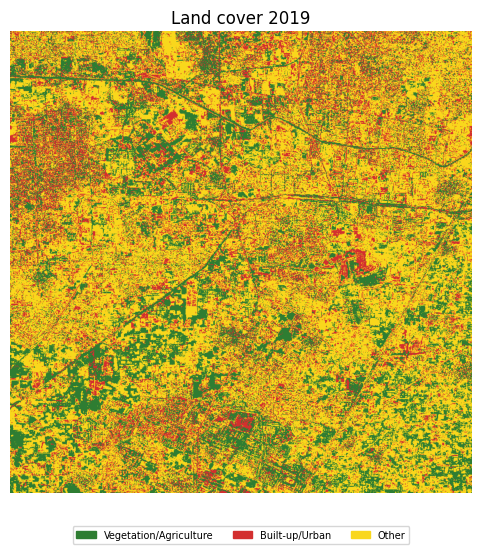

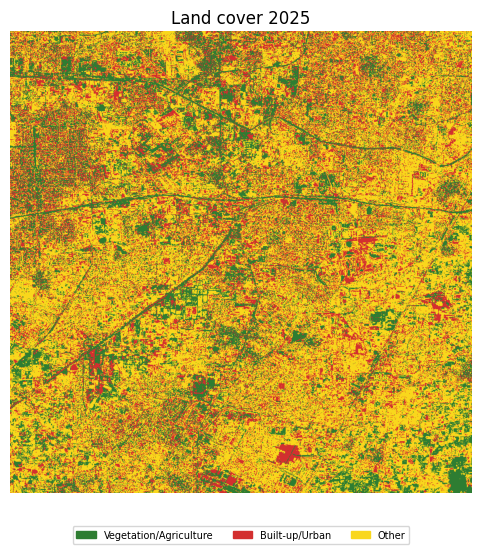

In [12]:
LABEL_MAP = {'vegetation': 0, 'veg': 0, 'vegetation/agriculture': 0, 'agriculture': 0, '0': 0,
             'built-up': 1, 'builtup': 1, 'built': 1, 'urban': 1, '1': 1,
             'other': 2, '2': 2}
def norm_label(x):
    s = str(x).strip().lower()
    s = s[:-2] if s.endswith('.0') else s
    return LABEL_MAP.get(s, None)

FEATURES = ['B2', 'B3', 'B4', 'B8', 'B11', 'NDVI', 'NDBI']
cls1, cls2 = cls1_rule, cls2_rule
METHOD = 'Rule-based (NDVI/NDBI thresholds)'
RF_ACC = None
tr_path = f'{OUT}/training_points_labeled.csv'
if os.path.exists(tr_path):
    tr = pd.read_csv(tr_path)
    tr['class'] = tr['label'].map(norm_label)
    tr = tr.dropna(subset=['class']).astype({'class': int})
    print('Training samples per class:\n', tr['class'].value_counts().sort_index())
    fc = ee.FeatureCollection([ee.Feature(ee.Geometry.Point([float(r['lon']), float(r['lat'])]), {'class': int(r['class'])})
                               for _, r in tr.iterrows()])
    samples = im2.select(FEATURES).sampleRegions(collection=fc, properties=['class'], scale=10, tileScale=4).randomColumn('r', 42)
    trn, tst = samples.filter(ee.Filter.lt('r', 0.7)), samples.filter(ee.Filter.gte('r', 0.7))
    rf_tmp = ee.Classifier.smileRandomForest(numberOfTrees=200, seed=42).train(trn, 'class', FEATURES)
    RF_ACC = tst.classify(rf_tmp).errorMatrix('class', 'classification').accuracy().getInfo()
    print(f'Hold-out (30%) accuracy of RF on training samples: {RF_ACC:.3f}')
    rf = ee.Classifier.smileRandomForest(numberOfTrees=200, seed=42).train(samples, 'class', FEATURES)
    def rf_map(img):
        return img.select(FEATURES).classify(rf).rename('class').toByte().updateMask(img.select('B4').mask())
    cls1, cls2 = rf_map(im1), rf_map(im2)
    METHOD = f'Random Forest (200 trees; features: {", ".join(FEATURES)}), trained on {len(tr)} manually labelled points from {Y2}'
else:
    print('⚠️ No labelled training file found – using rule-based classification.')
print('METHOD =', METHOD)

save_map(cls1, CLS_VIS, f'Land cover {Y1}', f'class_{Y1}', legend=True)
save_map(cls2, CLS_VIS, f'Land cover {Y2}', f'class_{Y2}', legend=True)

## Step 8 – Change detection (Vegetation/Agriculture → Built-up) + area statistics

,Metric,Value
0,Total AOI area (sq km),127.76
1,Valid (cloud-free in both years) area (sq km),127.65
2,Vegetation/Agriculture area 2019 (sq km),34.84
3,Vegetation/Agriculture area 2025 (sq km),29.79
4,Built-up area 2019 (sq km),24.50
5,Built-up area 2025 (sq km),30.68
6,Other area 2019 (sq km),68.31
7,Other area 2025 (sq km),67.17
8,Possible agriculture-to-urban conversion (sq km),7.24
9,% of AOI affected,5.67


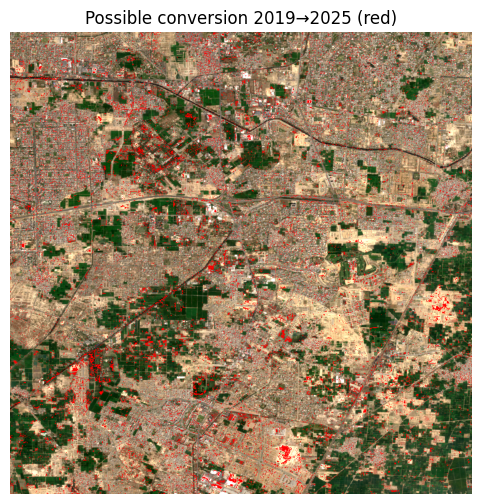

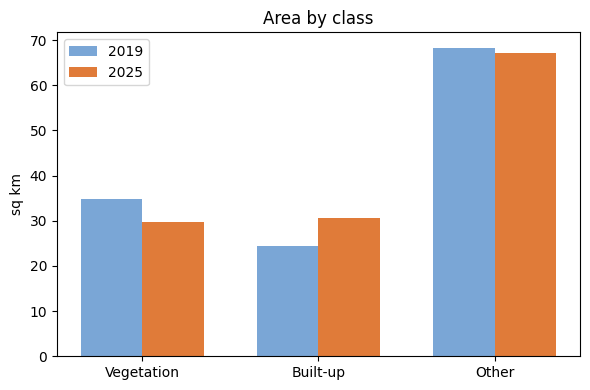

,rank,lon,lat,conversion_sq_km,pct_of_1sqkm_cell
0,1,423400.0,3466400.0,0.135,13.5
1,2,428400.0,3464400.0,0.109,10.9
2,3,423400.0,3465400.0,0.106,10.6
3,4,424400.0,3473400.0,0.102,10.2
4,5,426400.0,3463400.0,0.101,10.1
5,6,425400.0,3471400.0,0.096,9.6
6,7,425400.0,3472400.0,0.090,9.0
7,8,428400.0,3467400.0,0.089,8.9
8,9,426400.0,3464400.0,0.089,8.9
9,10,424400.0,3466400.0,0.086,8.6


In [13]:
c1, c2 = cls1.unmask(255), cls2.unmask(255)
conv = c1.eq(0).And(c2.eq(1)).rename('conversion')        # possible agricultural-to-urban conversion
rev = c1.eq(1).And(c2.eq(0))                               # built-up -> vegetation (mostly noise; useful for error discussion)
pa = ee.Image.pixelArea().divide(1e6)

def km2(mask):
    return pa.updateMask(mask).reduceRegion(reducer=ee.Reducer.sum(), geometry=aoi, scale=10,
                                            maxPixels=1e10, tileScale=4).get('area')

stats = ee.Dictionary({
    'total_aoi': aoi.area(1).divide(1e6),
    'valid_both': km2(c1.neq(255).And(c2.neq(255))),
    'veg_y1': km2(c1.eq(0)), 'built_y1': km2(c1.eq(1)), 'other_y1': km2(c1.eq(2)),
    'veg_y2': km2(c2.eq(0)), 'built_y2': km2(c2.eq(1)), 'other_y2': km2(c2.eq(2)),
    'converted': km2(conv), 'built_to_veg': km2(rev)}).getInfo()
S = {k: round(v or 0, 2) for k, v in stats.items()}
S['pct_aoi_converted'] = round(100 * S['converted'] / S['total_aoi'], 2)
S['pct_veg_y1_converted'] = round(100 * S['converted'] / S['veg_y1'], 2) if S['veg_y1'] else 0

stat_tbl = pd.DataFrame([
    ('Total AOI area (sq km)', S['total_aoi']),
    ('Valid (cloud-free in both years) area (sq km)', S['valid_both']),
    (f'Vegetation/Agriculture area {Y1} (sq km)', S['veg_y1']),
    (f'Vegetation/Agriculture area {Y2} (sq km)', S['veg_y2']),
    (f'Built-up area {Y1} (sq km)', S['built_y1']),
    (f'Built-up area {Y2} (sq km)', S['built_y2']),
    (f'Other area {Y1} (sq km)', S['other_y1']),
    (f'Other area {Y2} (sq km)', S['other_y2']),
    ('Possible agriculture-to-urban conversion (sq km)', S['converted']),
    ('% of AOI affected', S['pct_aoi_converted']),
    (f'% of {Y1} vegetation possibly converted', S['pct_veg_y1_converted']),
    ('Built-up → vegetation (likely noise) (sq km)', S['built_to_veg'])], columns=['Metric', 'Value'])
stat_tbl.to_csv(f'{OUT}/area_stats.csv', index=False)
display(stat_tbl)

# ---- change map (bright red over recent-year RGB) ----
base = im2.visualize(**RGB_VIS)
overlay = conv.selfMask().visualize(palette=['ff0000'])
save_map(base.blend(overlay), None, f'Possible conversion {Y1}→{Y2} (red)', 'change')

# ---- area chart ----
fig, ax = plt.subplots(figsize=(6, 4)); w = 0.35; x = np.arange(3)
ax.bar(x - w/2, [S['veg_y1'], S['built_y1'], S['other_y1']], w, label=str(Y1), color='#7aa6d6')
ax.bar(x + w/2, [S['veg_y2'], S['built_y2'], S['other_y2']], w, label=str(Y2), color='#e07b39')
ax.set_xticks(x); ax.set_xticklabels(['Vegetation', 'Built-up', 'Other']); ax.set_ylabel('sq km'); ax.legend(); ax.set_title('Area by class')
plt.tight_layout(); plt.savefig(f'{OUT}/maps/area_chart.png', dpi=150); plt.show()

# ---- hotspots: 1 km grid cells with highest conversion ----
grid = aoi.coveringGrid(ee.Projection('EPSG:32643'), 1000)
hs_fc = pa.updateMask(conv).rename('conv_km2').reduceRegions(collection=grid, reducer=ee.Reducer.sum(), scale=10, tileScale=4)
top_fc = hs_fc.sort('sum', False).limit(10)
top = top_fc.getInfo()['features']
HS = pd.DataFrame([dict(rank=i + 1,
                        lon=round(float(np.mean([c[0] for c in f['geometry']['coordinates'][0]])), 4),
                        lat=round(float(np.mean([c[1] for c in f['geometry']['coordinates'][0]])), 4),
                        conversion_sq_km=round(f['properties'].get('sum', 0) or 0, 3),
                        pct_of_1sqkm_cell=round(100 * (f['properties'].get('sum', 0) or 0), 1)) for i, f in enumerate(top)])
HS.to_csv(f'{OUT}/hotspots.csv', index=False)
json.dump({'type': 'FeatureCollection', 'features': top}, open(f'{OUT}/hotspots.geojson', 'w'))
display(HS)

## Step 9 – Validation (≥ 50 manually checked points)

In [14]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, cohen_kappa_score
va = pd.read_csv(f'{OUT}/validation_points_labeled.csv')
va['actual'] = va['actual_class'].map(norm_label)
va = va.dropna(subset=['actual']).astype({'actual': int}).reset_index(drop=True)
print('Labelled validation points:', len(va)); assert len(va) >= 50, 'Label at least 50 points'

fc = ee.FeatureCollection([ee.Feature(ee.Geometry.Point([float(r.lon), float(r.lat)]),
                                      {'point_id': int(r.point_id), 'actual': int(r.actual)}) for r in va.itertuples()])
probe = im2.select(['NDVI', 'NDBI']).addBands(cls2.rename('pred'))
res = probe.sampleRegions(collection=fc, properties=['point_id', 'actual'], scale=10, tileScale=4).getInfo()
df = pd.DataFrame([f['properties'] for f in res['features']]).dropna(subset=['pred'])
df = df.astype({'pred': int, 'actual': int, 'point_id': int}).merge(va[['point_id', 'notes']], on='point_id', how='left')
print('Points dropped because pixel was masked (cloud/no data):', len(va) - len(df))
df['Actual'] = df.actual.map(NAMES); df['Predicted'] = df.pred.map(NAMES)
df['Result'] = np.where(df.actual == df.pred, 'Correct', 'Incorrect')

acc = accuracy_score(df.actual, df.pred); kappa = cohen_kappa_score(df.actual, df.pred)
M = dict(n=int(len(df)), correct=int((df.Result == 'Correct').sum()), incorrect=int((df.Result == 'Incorrect').sum()),
         accuracy=round(acc * 100, 1), kappa=round(kappa, 3), rf_holdout=None if RF_ACC is None else round(RF_ACC * 100, 1))
json.dump(M, open(f'{OUT}/metrics.json', 'w'))
print(M)
cm = pd.DataFrame(confusion_matrix(df.actual, df.pred, labels=[0, 1, 2]),
                  index=[f'Actual {NAMES[i]}' for i in range(3)], columns=[f'Pred {NAMES[i]}' for i in range(3)])
display(cm)
print(classification_report(df.actual, df.pred, labels=[0, 1, 2], target_names=list(NAMES.values()), zero_division=0))
val_tbl = df[['point_id', 'Actual', 'Predicted', 'Result', 'notes']].rename(columns={'point_id': 'Point ID', 'notes': 'Notes'})
val_tbl.to_csv(f'{OUT}/validation_results.csv', index=False)
display(val_tbl)

Labelled validation points: 59
Points dropped because pixel was masked (cloud/no data): 0
{'n': 59, 'correct': 19, 'incorrect': 40, 'accuracy': 32.2, 'kappa': np.float64(0.038), 'rf_holdout': 39.2}


,Pred Vegetation/Agriculture,Pred Built-up/Urban,Pred Other
Actual Vegetation/Agriculture,10,6,18
Actual Built-up/Urban,4,5,7
Actual Other,2,3,4


                        precision    recall  f1-score   support

Vegetation/Agriculture       0.62      0.29      0.40        34
        Built-up/Urban       0.36      0.31      0.33        16
                 Other       0.14      0.44      0.21         9

              accuracy                           0.32        59
             macro avg       0.37      0.35      0.31        59
          weighted avg       0.48      0.32      0.35        59



,Point ID,Actual,Predicted,Result,Notes
0,1,Vegetation/Agriculture,Other,Incorrect,crop field
1,2,Vegetation/Agriculture,Other,Incorrect,crop field
2,3,Vegetation/Agriculture,Vegetation/Agriculture,Correct,crop field
3,4,Vegetation/Agriculture,Built-up/Urban,Incorrect,crop field
4,5,Vegetation/Agriculture,Other,Incorrect,crop field
5,6,Vegetation/Agriculture,Vegetation/Agriculture,Correct,crop field
6,7,Vegetation/Agriculture,Built-up/Urban,Incorrect,crop field
7,8,Vegetation/Agriculture,Built-up/Urban,Incorrect,crop field
8,9,Vegetation/Agriculture,Other,Incorrect,crop field
9,10,Vegetation/Agriculture,Other,Incorrect,crop field


## Step 10 – Error analysis (≥ 15 weak / incorrect cases)
Incorrect points + borderline points (index values very close to a threshold). The "suggested reason" is only a *hint* – **look at each point on the satellite basemap and edit the reason yourself**.

In [15]:
REASONS = {(0, 1): 'Dry/fallow field or bare soil looks like built-up (low NDVI, high NDBI); harvest-season change',
           (0, 2): 'Sparse crop/young crop or mixed pixel -> NDVI below vegetation threshold',
           (1, 0): 'Tree-covered housing area / park or mixed pixel classified as vegetation',
           (1, 2): 'Small buildings or new roads missed; 10 m mixed pixels',
           (2, 0): 'Seasonal grass/scrub classified as vegetation',
           (2, 1): 'Barren/sandy soil or dry channel confused with built-up'}
df['near_threshold'] = (((df.NDVI - THR['ndvi_veg']).abs() < 0.05) | ((df.NDVI - THR['ndvi_built_max']).abs() < 0.05) |
                        ((df.NDBI - THR['ndbi_built']).abs() < 0.03))
err = df[(df.Result == 'Incorrect') | df.near_threshold].copy()
err = err.sort_values('Result', ascending=False)   # 'Incorrect' first
err['Error type'] = np.where(err.Result == 'Incorrect', err.Actual + ' → ' + err.Predicted, 'Borderline (weak) case')
err['Possible reason (VERIFY & rewrite)'] = [REASONS.get((a, p), 'Index close to threshold') if r == 'Incorrect'
                                              else 'NDVI/NDBI very close to threshold; mixed pixel or seasonal effect'
                                              for a, p, r in zip(err.actual, err.pred, err.Result)]
err_tbl = err[['point_id', 'Actual', 'Predicted', 'Error type', 'NDVI', 'NDBI', 'notes', 'Possible reason (VERIFY & rewrite)']].round(3)
err_tbl.to_csv(f'{OUT}/error_analysis.csv', index=False)
print(f'{len(err_tbl)} weak/incorrect cases', '✔' if len(err_tbl) >= 15 else '⚠️ need >= 15: label more validation points')
display(err_tbl)

49 weak/incorrect cases ✔


,point_id,Actual,Predicted,Error type,NDVI,NDBI,notes,Possible reason (VERIFY & rewrite)
0,1,Vegetation/Agriculture,Other,Vegetation/Agriculture → Other,0.698,-0.169,crop field,Sparse crop/young crop or mixed pixel -> NDVI ...
42,43,Vegetation/Agriculture,Built-up/Urban,Vegetation/Agriculture → Built-up/Urban,0.522,-0.117,crop field,Dry/fallow field or bare soil looks like built...
29,30,Built-up/Urban,Other,Built-up/Urban → Other,0.379,-0.102,housingarea,Small buildings or new roads missed; 10 m mixe...
34,35,Other,Built-up/Urban,Other → Built-up/Urban,0.299,0.055,baresoil,Barren/sandy soil or dry channel confused with...
35,36,Other,Vegetation/Agriculture,Other → Vegetation/Agriculture,0.093,0.092,baresoil,Seasonal grass/scrub classified as vegetation
36,37,Other,Vegetation/Agriculture,Other → Vegetation/Agriculture,0.069,0.091,baresoil,Seasonal grass/scrub classified as vegetation
37,38,Other,Built-up/Urban,Other → Built-up/Urban,0.486,-0.130,baresoil,Barren/sandy soil or dry channel confused with...
39,40,Other,Built-up/Urban,Other → Built-up/Urban,0.560,-0.174,baresoil,Barren/sandy soil or dry channel confused with...
40,41,Vegetation/Agriculture,Other,Vegetation/Agriculture → Other,0.316,-0.091,crop field,Sparse crop/young crop or mixed pixel -> NDVI ...
41,42,Vegetation/Agriculture,Other,Vegetation/Agriculture → Other,0.121,0.064,crop field,Sparse crop/young crop or mixed pixel -> NDVI ...


## Step 11 – Interactive map (toggle layers) → `interactive_map.html`

In [16]:
m = geemap.Map(); m.centerObject(aoi, 12); m.add_basemap('SATELLITE')
m.addLayer(im1, RGB_VIS, f'RGB {Y1}', False)
m.addLayer(im2, RGB_VIS, f'RGB {Y2}', False)
m.addLayer(im1.select('NDVI'), NDVI_VIS, f'NDVI {Y1}', False)
m.addLayer(im2.select('NDVI'), NDVI_VIS, f'NDVI {Y2}', False)
m.addLayer(im1.select('NDBI'), NDBI_VIS, f'NDBI {Y1}', False)
m.addLayer(im2.select('NDBI'), NDBI_VIS, f'NDBI {Y2}', False)
m.addLayer(cls1, CLS_VIS, f'Land cover {Y1}', False)
m.addLayer(cls2, CLS_VIS, f'Land cover {Y2}', False)
m.addLayer(conv.selfMask(), {'palette': ['ff0000']}, f'Possible conversion {Y1}→{Y2}', True)
m.addLayer(top_fc.style(color='ffff00', fillColor='00000000', width=2), {}, 'Top-10 hotspot cells', True)
m.addLayer(ee.FeatureCollection([ee.Feature(aoi)]).style(color='00ffff', fillColor='00000000'), {}, 'AOI boundary', True)
m.add_layer_control()
m.to_html(f'{OUT}/interactive_map.html')
m

Map(center=[31.35500100659, 74.23500000000168], controls=(WidgetControl(options=['position', 'transparent_bg']…

## Step 12 – Auto-generate report + LinkedIn post (then **rewrite in your own words**)

In [17]:
obs = (f"- Estimated **{S['converted']} sq km** ({S['pct_aoi_converted']}% of the AOI) shows *possible* conversion from vegetation/agriculture to built-up between {Y1} and {Y2}.\n"
       f"- Built-up area changed from {S['built_y1']} to {S['built_y2']} sq km; vegetation from {S['veg_y1']} to {S['veg_y2']} sq km.\n"
       f"- Strongest detected change cell is near ({HS.lat.iloc[0]}, {HS.lon.iloc[0]}) with {HS.conversion_sq_km.iloc[0]} sq km.\n"
       f"- Validation accuracy ≈ {M['accuracy']}% on {M['n']} manually checked points (kappa {M['kappa']}). Results are estimates and may include false conversions.\n")
open(f'{OUT}/observations.md', 'w').write(obs)

report = f"""# Punjab GeoGuardian – Detecting Urban Expansion and Farmland Loss Using Sentinel-2

> Learning prototype – not an official government monitoring system. All results are *estimated* / *possible* changes.

## 1. Project Overview
This project uses satellite imagery to detect possible urban expansion and farmland loss in **{AOI_NAME}**. Sentinel-2 images of {Y1} and {Y2} are compared, vegetation and built-up indices are computed, land cover is classified, and areas where vegetation/agriculture appears to have changed into built-up land are highlighted and measured. Outputs: maps, area statistics, an interactive map and a dashboard.

## 2. Tools and Technologies
Python, Google Colab, Google Earth Engine, Sentinel-2 SR Harmonized, geemap/Folium, Pandas, NumPy, Matplotlib, Scikit-learn, Random Forest (Earth Engine), Streamlit.

## 3. Area and Data Selection
- **AOI:** {AOI_NAME}, bounding box {AOI_BBOX} (≈ {S['total_aoi']} sq km). A peri-urban belt of Lahore with active housing/commercial development on former farmland.
- **Years:** {Y1} ({DATE_RANGES[Y1][0]} to {DATE_RANGES[Y1][1]}, {n1} scenes) and {Y2} ({DATE_RANGES[Y2][0]} to {DATE_RANGES[Y2][1]}, {n2} scenes).
- **Satellite:** Sentinel-2 Level-2A (10 m), scene cloud filter < {CLOUD_MAX}%, SCL pixel-level cloud/shadow mask, median composite. Same season used in both years to reduce crop-calendar effects.

## 4. Remote-Sensing Concepts
**NDVI** = (NIR − Red) / (NIR + Red) (Sentinel-2: B8, B4). Healthy vegetation reflects strongly in NIR and absorbs red light, so high NDVI usually means crops/vegetation.

**NDBI** = (SWIR − NIR) / (SWIR + NIR) (B11, B8). Built-up surfaces reflect more SWIR than NIR, so higher NDBI often indicates built-up land (bare soil can also give high values).

**Change detection** compares classified maps of two dates: pixels that were *Vegetation/Agriculture* in {Y1} and *Built-up* in {Y2} are marked as possible agricultural-to-urban conversion.

## 5. Methodology
AOI selection → Sentinel-2 loading → date + cloud filtering → median composite & clip → RGB → NDVI/NDBI/MNDWI → classification ({METHOD}) → change detection → area calculation (pixel area, 10 m) → hotspot grid (1 km cells) → maps/dashboard → validation → error analysis.
Thresholds used for the baseline rules: {THR}.

## 6. Results
| Metric | Value |
|---|---|
{chr(10).join(f'| {a} | {b} |' for a, b in stat_tbl.values)}

![RGB {Y1}](maps/rgb_{Y1}.png) ![RGB {Y2}](maps/rgb_{Y2}.png)

![NDVI {Y1}](maps/ndvi_{Y1}.png) ![NDVI {Y2}](maps/ndvi_{Y2}.png)

![NDBI {Y1}](maps/ndbi_{Y1}.png) ![NDBI {Y2}](maps/ndbi_{Y2}.png)

![Class {Y1}](maps/class_{Y1}.png) ![Class {Y2}](maps/class_{Y2}.png)

![Change](maps/change.png) ![Areas](maps/area_chart.png)

**Top hotspot cells (1 sq km grid):**

{HS.to_markdown(index=False)}

## 7. Validation
{M['n']} manually checked points (stratified random, checked against Google high-resolution satellite basemap; not used for training). Correct: {M['correct']}, incorrect: {M['incorrect']}, **approximate accuracy: {M['accuracy']}%**, Cohen's kappa {M['kappa']}. Full table: `validation_results.csv`.

{val_tbl.head(60).to_markdown(index=False)}

## 8. Error Analysis
{len(err_tbl)} weak/incorrect cases were reviewed (table below, full list in `error_analysis.csv`).

{err_tbl.to_markdown(index=False)}

**Suggested improvements:** (1) more and better-distributed training samples; (2) multi-season / same-month composites and stricter cloud filtering; (3) higher-resolution imagery or a U-Net segmentation model; (4) more land classes (water, barren, roads); (5) validate against official housing-scheme/land-use data; (6) use more than two years.

## 9. Limitations
10 m pixels mix surfaces; dry fields/bare soil can look like built-up; tree-covered housing can look like vegetation; accuracy depends on dates, cloud masking, thresholds and sample quality. Results show *possible conversion* only and make no claim about any specific society or owner.

## 10. What I Learned
Using satellite imagery in AI projects, selecting an AOI, NDVI/NDBI, land classification, change detection, area estimation and map-based outputs.
"""
open(f'{OUT}/report.md', 'w').write(report)

import markdown
html = markdown.markdown(report, extensions=['tables'])
def embed(mo):
    return 'src="data:image/png;base64,' + base64.b64encode(open(f'{OUT}/{mo.group(1)}', 'rb').read()).decode() + '"'
html = re.sub(r'src="(maps/[^"]+)"', embed, html)
open(f'{OUT}/report.html', 'w').write(f'<html><head><meta charset="utf-8"><style>body{{font-family:Arial;max-width:900px;margin:auto;font-size:13px}}img{{width:48%}}table{{border-collapse:collapse}}td,th{{border:1px solid #999;padding:3px 6px;font-size:11px}}</style></head><body>{html}</body></html>')

linkedin = f"""Today, I completed AIRI Team PITB - AI Internship Task 3, where I built an end-to-end GeoAI project using satellite imagery and machine learning.

For this task, I developed Punjab GeoGuardian, a prototype that detects possible urban expansion and farmland loss in {AOI_NAME} by comparing Sentinel-2 imagery from {Y1} and {Y2}.

Key results (estimated): about {S['converted']} sq km ({S['pct_aoi_converted']}% of the AOI) shows possible conversion from vegetation/agriculture to built-up land. Validation on {M['n']} manually checked points gave ≈ {M['accuracy']}% accuracy.

The project covered the complete GeoAI workflow:
- Area of Interest selection
- Satellite imagery collection
- NDVI and NDBI calculation
- Land-use classification
- Change detection
- Area estimation
- Map visualization
- Validation and error analysis
- Final documentation

Tools used: Python, Google Colab, Google Earth Engine, Sentinel-2, Geemap/Folium, Scikit-learn, Streamlit.

Key learning: AI becomes more powerful when it is connected with real-world geography, public data, and decision-making problems.

#GeoAI #RemoteSensing #SatelliteImagery #MachineLearning #UrbanPlanning #Agriculture #Python #GoogleEarthEngine #AIRI #PITB #AIInternship"""
open(f'{OUT}/linkedin_post.md', 'w').write(linkedin)
print('Saved report.md, report.html (open → Print → Save as PDF), linkedin_post.md in', OUT)

Saved report.md, report.html (open → Print → Save as PDF), linkedin_post.md in /content/drive/MyDrive/PunjabGeoGuardian/outputs
